# Bases del residuo: dimensión fija y rango adaptativo

Diez semillas emparejadas, 100 pasos comunes y 10000 de continuación. Cada variante usa 32 puntos guiados y 96 Sobol. Red, pérdida histórica datos+PDE+IC, candidatos y ventana permanecen iguales al notebook 15. Sobol y dimensión 4 se reutilizan desde los artefactos auditados; manifest.json registra su procedencia.

## Definiciones

Etapa 1: dimensiones totales 2, 4, 8 y 12; la media ocupa una dirección en PCA + media. Etapa 2: umbrales 95%, 99% y 99.9% sobre suma de valores singulares al cuadrado. POD conserva energía sin centrar; PCA conserva varianza centrada. PCA + media selecciona primero los componentes por varianza y añade la media si es independiente: su dimensión total puede ser mayor. Se registra la fracción realmente representada. No se rellenan bases sin rango suficiente; esos casos se declaran inviables. El rango adaptativo puede cambiar en cada actualización.

## Etapa 1: dimensión fija

| Base | Parámetro | Semillas completas | Validación RMSE | Prueba RMSE | Residuo | Rango medio |
|---|---:|---:|---:|---:|---:|---:|
| POD | 2 | 10/10 | 0.12532 | 0.13024 | 0.14178 | 2.00000 |
| PCA centrada | 2 | 10/10 | 0.09802 | 0.10274 | 0.14825 | 2.00000 |
| PCA + media | 2 | 10/10 | 0.09399 | 0.10015 | 0.12015 | 2.00000 |
| POD | 4 | 10/10 | 0.11148 | 0.11304 | 0.12041 | 4.00000 |
| PCA centrada | 4 | 10/10 | 0.09254 | 0.09508 | 0.13799 | 4.00000 |
| PCA + media | 4 | 10/10 | 0.08518 | 0.08846 | 0.12084 | 4.00000 |
| POD | 8 | 10/10 | 0.08482 | 0.08930 | 0.11494 | 8.00000 |
| PCA centrada | 8 | 10/10 | 0.08061 | 0.08701 | 0.11891 | 8.00000 |
| PCA + media | 8 | 10/10 | 0.08448 | 0.08714 | 0.10091 | 8.00000 |
| POD | 12 | 10/10 | 0.08842 | 0.08908 | 0.10132 | 12.00000 |
| PCA centrada | 12 | 10/10 | 0.09449 | 0.10112 | 0.11654 | 12.00000 |
| PCA + media | 12 | 10/10 | 0.09033 | 0.09631 | 0.10305 | 12.00000 |

Las configuraciones incompletas no participan en la elección. La selección usa únicamente RMSE terminal de validación medio; las métricas de prueba describen el resultado y no deciden parámetros.

**fixed**

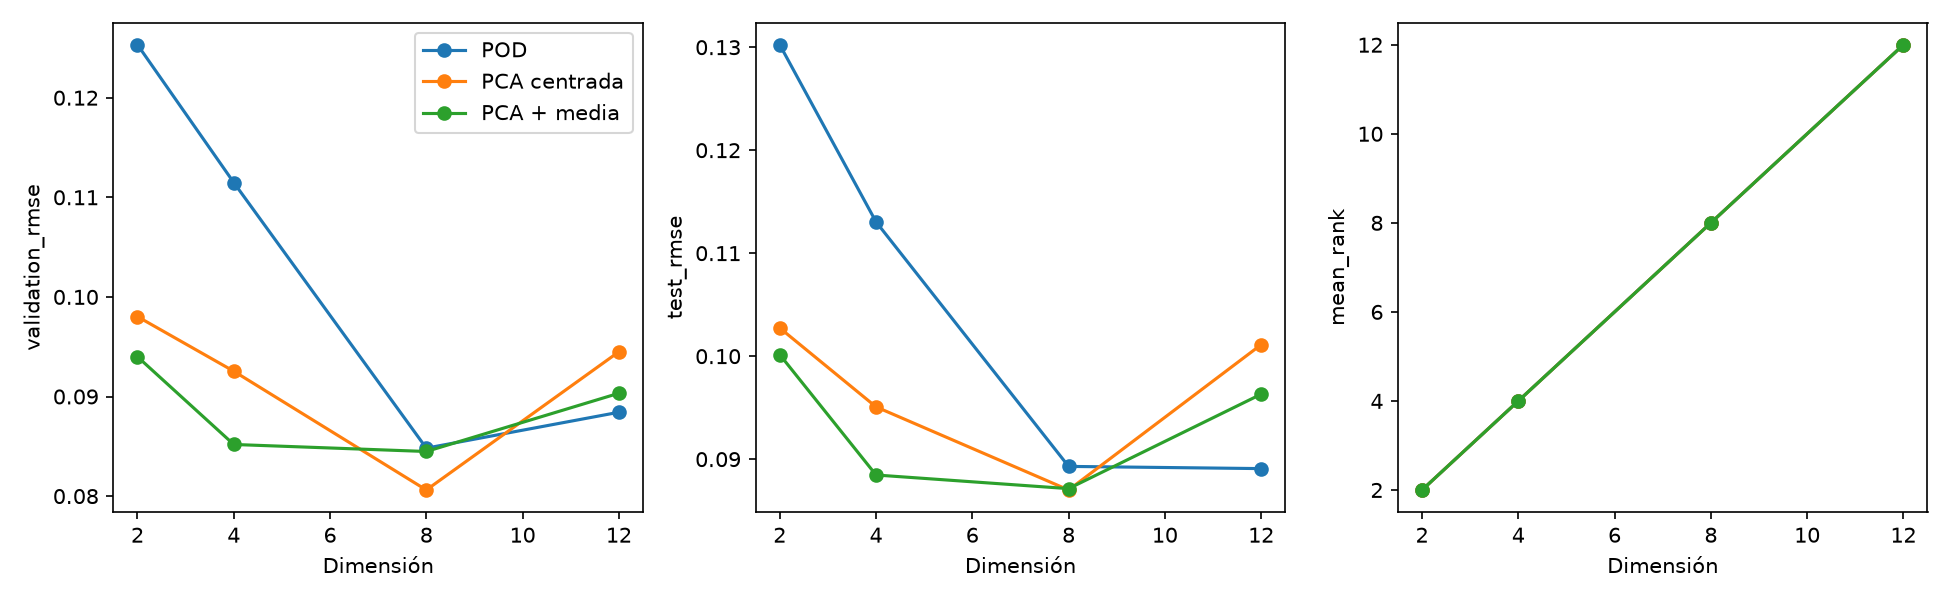

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/rank_study/two_stage_10_seeds_10k_v1/fixed.png'), format='png', embed=True))


## Etapa 2: rango adaptativo

| Base | Parámetro | Semillas completas | Validación RMSE | Prueba RMSE | Residuo | Rango medio |
|---|---:|---:|---:|---:|---:|---:|
| POD | 0.95 | 10/10 | 0.10095 | 0.10399 | 0.12114 | 7.67400 |
| PCA centrada | 0.95 | 10/10 | 0.08223 | 0.08826 | 0.10594 | 11.89400 |
| PCA + media | 0.95 | 10/10 | 0.07676 | 0.08320 | 0.09586 | 12.74600 |
| POD | 0.99 | 10/10 | 0.07750 | 0.07802 | 0.10090 | 12.89900 |
| PCA centrada | 0.99 | 10/10 | 0.08222 | 0.08586 | 0.10415 | 15.49200 |
| PCA + media | 0.99 | 10/10 | 0.07979 | 0.08337 | 0.09348 | 16.27200 |
| POD | 0.999 | 10/10 | 0.09230 | 0.09435 | 0.09849 | 17.15400 |
| PCA centrada | 0.999 | 10/10 | 0.07924 | 0.08365 | 0.09853 | 17.57800 |
| PCA + media | 0.999 | 10/10 | 0.09270 | 0.09583 | 0.10328 | 18.53400 |

Las configuraciones incompletas no participan en la elección. La selección usa únicamente RMSE terminal de validación medio; las métricas de prueba describen el resultado y no deciden parámetros.

**adaptive**

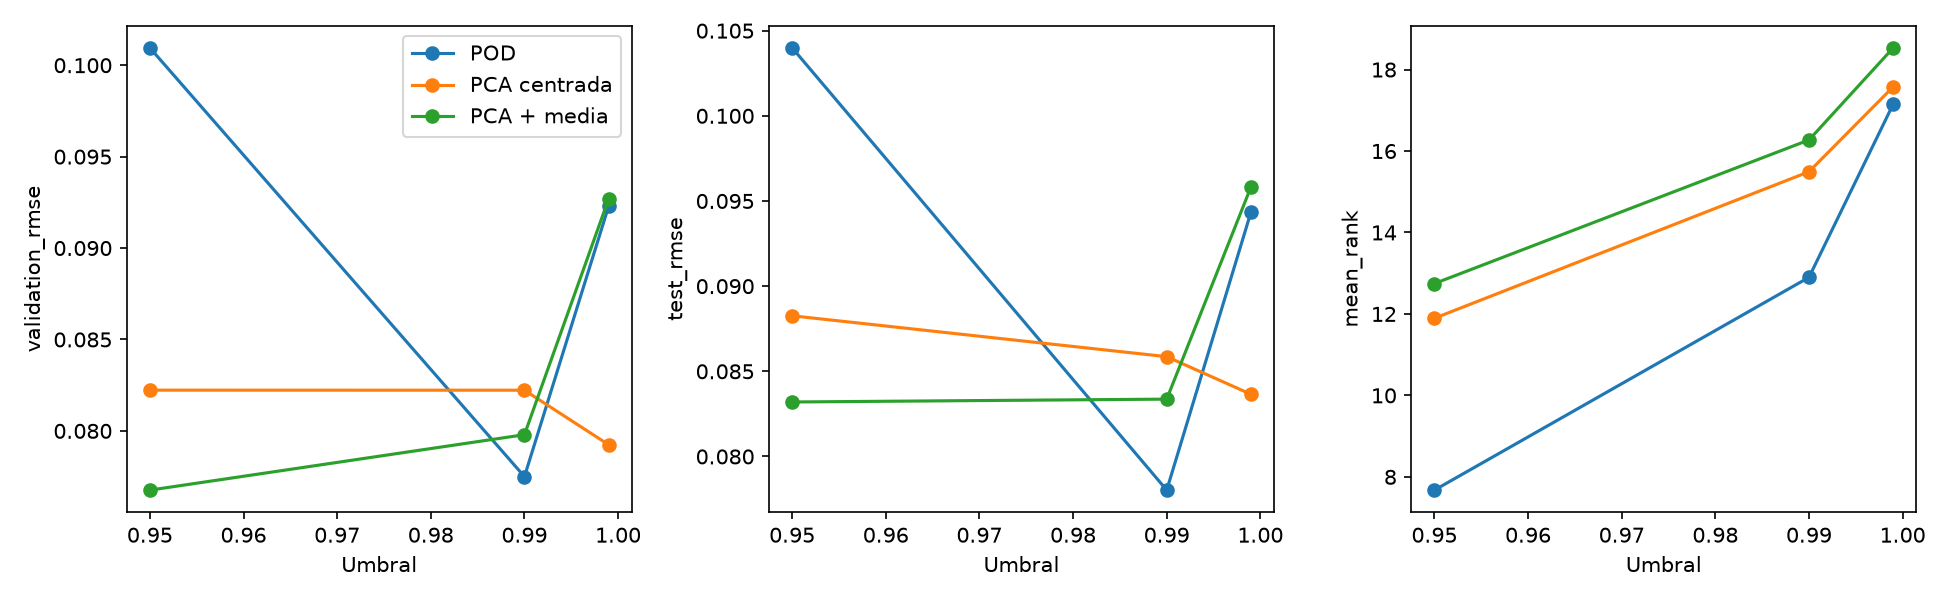

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/rank_study/two_stage_10_seeds_10k_v1/adaptive.png'), format='png', embed=True))


## Elección por validación

{
  "fixed": {
    "id": "fixed_8_pca_qr",
    "stage": "fixed",
    "method": "pca_qr",
    "parameter": 8,
    "completed": 10,
    "validation_rmse": 0.08061433658003807,
    "test_rmse": 0.08700729347765446,
    "residual": 0.11891037300229072,
    "mean_rank": 8.0
  },
  "adaptive": {
    "id": "adaptive_0p95_pca_mean_qr",
    "stage": "adaptive",
    "method": "pca_mean_qr",
    "parameter": 0.95,
    "completed": 10,
    "validation_rmse": 0.07675956077873707,
    "test_rmse": 0.08319945856928826,
    "residual": 0.09585572630167008,
    "mean_rank": 12.745999999999999
  }
}

La elección es exploratoria sobre las mismas diez semillas. Una confirmación requiere nuevas semillas. Los tiempos de estas corridas incluyen diagnóstico y compilación. Los rangos por actualización están en selection_diagnostics.csv de cada corrida; results_by_seed.csv conserva dispersión y permite comparaciones pareadas.

Reproducir: `python scripts/run_collocation_rank_study.py`; regenerar: añadir `--report-only`.

## Corridas inviables

Todas las combinaciones completaron sus diez semillas.